# Segmentation client — étude de cas marketing

Question : quels profils d’achat le jeu public Customer Personality Analysis permet-il de distinguer ? Les résultats décrivent ce fichier historique et ne sont pas directement généralisables à une entreprise. `Response` et les réponses aux campagnes sont exclues du fit et servent uniquement à l’analyse post-clustering.

## 1. Audit de la donnée source

Le CSV original reste inchangé. On contrôle le schéma, les valeurs manquantes et les doublons avant de lancer la préparation.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from customer_segmentation.pipeline import charger_source, audit_source, entrainer_et_sauvegarder, FEATURES

brut = charger_source()
audit = audit_source(brut)
print('Dimensions :', brut.shape)
display(pd.Series(audit, dtype='object').to_frame('résultat'))
display(brut[FEATURES].describe().round(1))

Dimensions : (2240, 29)


,résultat
lignes_initiales,2240
colonnes_initiales,29
doublons_exacts,0
ids_dupliques,0
valeurs_manquantes,{'Income': 24}
annees_naissance_incoherentes,3


,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
count,2216.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0
mean,52247.3,49.1,303.9,26.3,167.0,37.5,27.1,44.0,2.3,4.1,2.7,5.8,5.3
std,25173.1,29.0,336.6,39.8,225.7,54.6,41.3,52.2,1.9,2.8,2.9,3.3,2.4
min,1730.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,35303.0,24.0,23.8,1.0,16.0,3.0,1.0,9.0,1.0,2.0,0.0,3.0,3.0
50%,51381.5,49.0,173.5,8.0,67.0,12.0,8.0,24.0,2.0,4.0,2.0,5.0,6.0
75%,68522.0,74.0,504.2,33.0,232.0,50.0,33.0,56.0,3.0,6.0,4.0,8.0,7.0
max,666666.0,99.0,1493.0,199.0,1725.0,259.0,263.0,362.0,15.0,27.0,28.0,13.0,20.0


## 2. Prétraitement ajusté sur la source

Le préprocesseur apprend l’imputation médiane et les plafonds financiers au 99e percentile. Il applique ensuite log1p aux revenus et dépenses asymétriques, puis une standardisation. Cet objet est sauvegardé dans le pipeline et réutilisé à l’identique lors de la prédiction, ce qui évite une divergence entre notebook et application.

,k,inertie,silhouette,davies_bouldin,calinski_harabasz,stabilite_ari_moyenne,stabilite_ari_ecart_type,stabilite_validee,selectionne
0,2,17421.830,0.346,1.169,1502.741,0.966,0.012,True,True
1,3,14519.876,0.277,1.520,1124.682,0.987,0.004,True,False
2,4,13692.391,0.189,1.875,839.788,0.703,0.175,False,False
3,5,12881.364,0.144,2.084,704.377,0.929,0.052,True,False
4,6,12237.739,0.144,2.032,616.372,0.938,0.008,True,False
5,7,11773.101,0.146,2.028,548.363,0.832,0.060,True,False
6,8,11348.112,0.132,2.020,499.351,0.838,0.091,True,False
7,9,10965.457,0.121,1.973,461.709,0.753,0.136,False,False


K retenu : 2
Pipeline enregistré : models/kmeans_pipeline.pkl


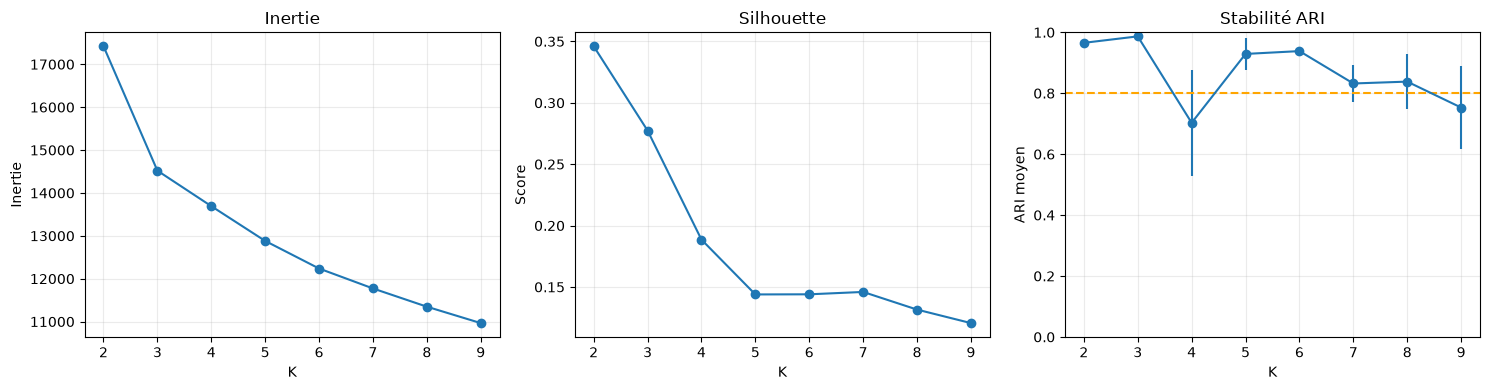

In [2]:
df, scores, pipeline, audit = entrainer_et_sauvegarder()
display(scores.round(3))
K = pipeline.named_steps['cluster'].n_clusters
print('K retenu :', K)
print('Pipeline enregistré : models/kmeans_pipeline.pkl')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(scores.k, scores.inertie, marker='o'); axes[0].set(title='Inertie', xlabel='K', ylabel='Inertie')
axes[1].plot(scores.k, scores.silhouette, marker='o'); axes[1].set(title='Silhouette', xlabel='K', ylabel='Score')
axes[2].errorbar(scores.k, scores.stabilite_ari_moyenne, yerr=scores.stabilite_ari_ecart_type, marker='o'); axes[2].axhline(.8, color='orange', linestyle='--'); axes[2].set(title='Stabilité ARI', xlabel='K', ylabel='ARI moyen', ylim=(0, 1))
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(ROOT / 'outputs' / 'comparaison_k.png', dpi=160, bbox_inches='tight'); plt.show()

## 3. Interpréter les segments

Les K candidats sont comparés par inertie, silhouette, Davies–Bouldin et Calinski–Harabasz. La stabilité ARI compare le modèle complet à quatre modèles ajustés sur 80 % des lignes. La règle de sélection choisit le meilleur score silhouette parmi les K dont l’ARI moyen atteint 0,80 ; si aucun K n’est assez stable, elle revient au meilleur score silhouette et ce point doit être signalé. Les numéros de cluster restent arbitraires.

,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age_approx,Response,Complain
cluster,,,,,,,,,,,,,,,,
0,67693.7,49.4,539.3,48.6,305.6,69.3,49.7,71.3,2.4,5.7,4.6,8.2,4.1,46.9,0.2,0.0
1,36856.5,48.8,71.1,4.3,29.7,6.1,4.7,17.0,2.3,2.5,0.7,3.4,6.5,43.4,0.1,0.0


,clients
cluster,
0,1114
1,1126


Taux de réponse observé, descriptif seulement :


,response (%)
cluster,
0,19.7
1,10.1


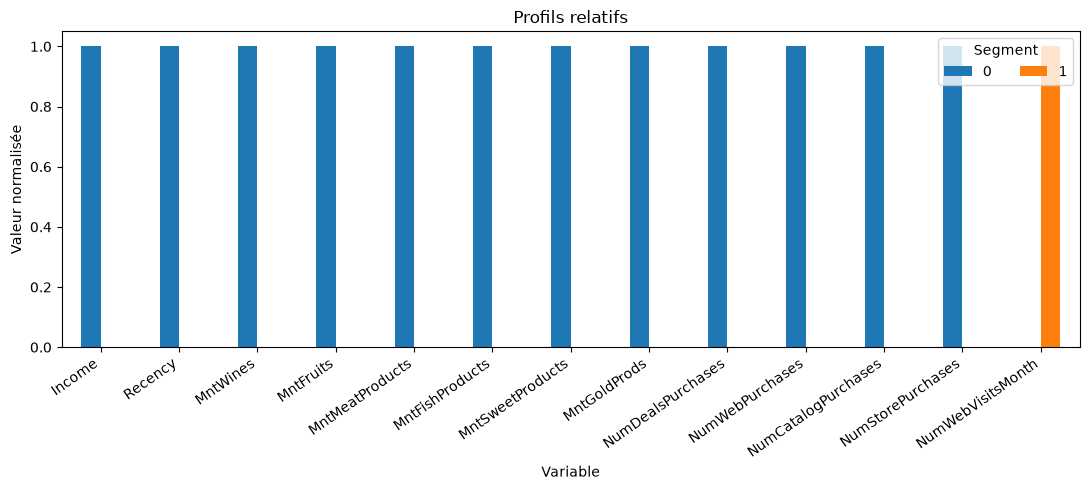

In [3]:
from customer_segmentation.pipeline import FEATURES
profils = df.groupby('cluster')[FEATURES + ['Age_approx', 'Response', 'Complain']].mean().round(1)
display(profils)
display(df.cluster.value_counts().sort_index().rename('clients').to_frame())
print('Taux de réponse observé, descriptif seulement :')
display((df.groupby('cluster').Response.mean() * 100).round(1).rename('response (%)').to_frame())
fig, ax = plt.subplots(figsize=(11, 5))
norm = (profils[FEATURES] - profils[FEATURES].min()) / (profils[FEATURES].max() - profils[FEATURES].min()).replace(0, 1)
norm.T.plot(kind='bar', ax=ax); ax.set(title='Profils relatifs', xlabel='Variable', ylabel='Valeur normalisée')
ax.legend(title='Segment', ncol=3); plt.xticks(rotation=35, ha='right'); plt.tight_layout()
fig.savefig(ROOT / 'outputs' / 'profils_segments.png', dpi=160, bbox_inches='tight'); plt.show()

## 4. Projection PCA et limites

La PCA réduit les 13 variables à deux axes pour visualiser. Le score silhouette est mesuré dans l’espace complet. Une relation entre cluster et réponse campagne ne prouve ni causalité ni efficacité d’une stratégie.

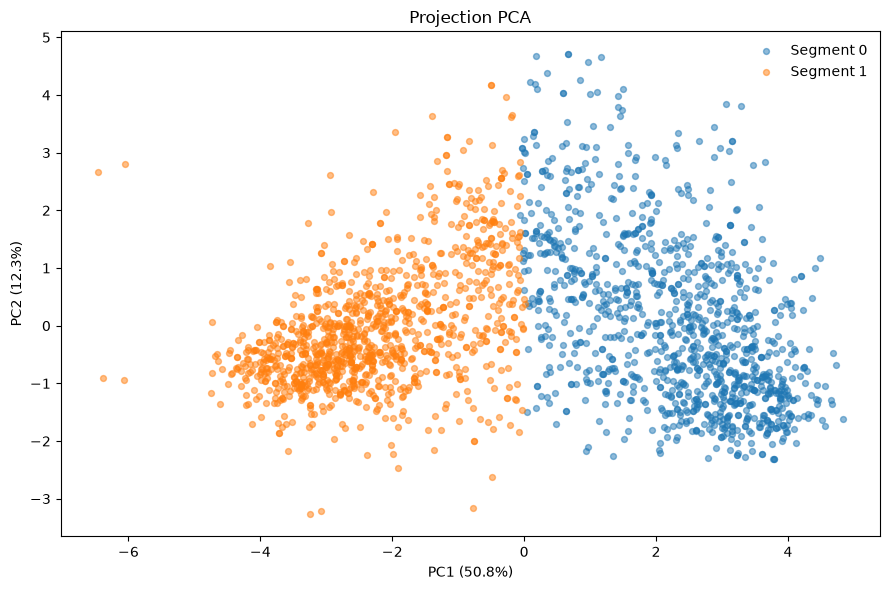

Variance capturée par les deux axes : 63.1%


In [4]:
from sklearn.decomposition import PCA
X_scaled = pipeline[:-1].transform(df[FEATURES])
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(9, 6))
for i in sorted(df.cluster.unique()):
    mask = df.cluster.to_numpy() == i
    ax.scatter(coords[mask, 0], coords[mask, 1], s=18, alpha=.5, label=f'Segment {i}')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', title='Projection PCA')
ax.legend(frameon=False); plt.tight_layout(); fig.savefig(ROOT / 'outputs' / 'clusters_pca_2d.png', dpi=160, bbox_inches='tight'); plt.show()
print(f'Variance capturée par les deux axes : {pca.explained_variance_ratio_.sum():.1%}')

## 5. Réexécuter et tracer le modèle

Toutes les cellules peuvent être rejouées avec **Restart & Run All**. En dehors du notebook, le même entraînement est disponible avec `python -m customer_segmentation.pipeline --data data/marketing_campaign.csv`. Les artefacts incluent le pipeline complet, les métriques par K, un rapport JSON avec empreinte SHA-256 du CSV et versions des bibliothèques.

Avant tout usage réel, confirmer la source et les droits, vérifier la représentativité, faire valider l’utilité métier et tester le modèle sur des données récentes autorisées.